# Model comparison on validation: logistic regression vs Naive Bayes vs decision tree

Workflow, also in `scripts/train_models.py`:
1. Fit every hyperparameter combination on **train**.
2. Keep the combination with the best **val PR-AUC**.
3. Pick that model's decision threshold to maximise **val F1**.

**Test splits are not used anywhere in this notebook.** Because the hyperparameters and thresholds are chosen on val, the val scores below are slightly optimistic. The honest final number will come from `test_main` later.

Re-create the saved models with `python3 scripts/train_models.py` (takes a while), or set `RUN_TUNING = True` below.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve().parents[1] if Path.cwd().name == "sofia" else Path.cwd().resolve()
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.models.data import load_models_config, load_modelling_frame, split_xy
from src.models.metrics import evaluate_scores, best_f1_threshold
from src.models import train as T

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
cfg = load_models_config(PROJECT_ROOT / "config" / "models.json")

# Only train and val are loaded. The loader refuses test_main / test_tail.
df = load_modelling_frame(PROJECT_ROOT / "data" / "processed", splits=("train", "val"))
X_train, y_train = split_xy(df, "train", cfg)
X_val, y_val = split_xy(df, "val", cfg)
print(f"train {len(X_train):,} rows | val {len(X_val):,} rows")

train 3,046,861 rows | val 1,015,602 rows


In [2]:
import pickle
RUN_TUNING = False
out = PROJECT_ROOT / "artifacts" / "models"
if RUN_TUNING or not (out / "decision_tree.pkl").exists():
    results = T.run_model_selection(cfg, X_train, y_train, X_val, y_val, progress=print)
    models = {n: {"pipeline": r["pipeline"], "threshold": r["threshold"], "params": r["best_params"]} for n, r in results.items()}
else:
    models = {n: pickle.load(open(out / f"{n}.pkl", "rb")) for n in T.MODEL_NAMES}
val_scores = {n: T.positive_scores(m["pipeline"], X_val) for n, m in models.items()}
{n: m["params"] for n, m in models.items()}

{'logistic_regression': {'class_weight': None, 'C': 10.0},
 'naive_bayes': {'var_smoothing': 1e-06},
 'decision_tree': {'max_depth': 32, 'min_samples_leaf': 50}}

## 1. Tuning grids
One row per configuration, best val PR-AUC first.

In [3]:
for n in T.MODEL_NAMES:
    print(f"\n=== {n} ===")
    display(pd.read_csv(out / f"grid_{n}.csv").head(8).round(4))


=== logistic_regression ===


,class_weight,C,train_pr_auc,val_pr_auc,fit_seconds
0,NaN,10.00,0.0233,0.0489,8.7
1,NaN,1.00,0.0233,0.0488,8.8
2,NaN,0.10,0.0229,0.0478,8.6
3,NaN,0.01,0.0217,0.0432,8.3
4,balanced,1.00,0.0162,0.0394,21.3
5,balanced,0.10,0.0159,0.0383,28.6
6,balanced,10.00,0.0160,0.0383,33.8
7,balanced,0.01,0.0159,0.0380,20.1



=== naive_bayes ===


,var_smoothing,train_pr_auc,val_pr_auc,fit_seconds
0,0.000,0.0089,0.0123,13.2
1,0.001,0.0084,0.0116,11.8
2,0.000,0.0069,0.0099,12.8
3,0.100,0.0045,0.0054,12.0



=== decision_tree ===


,max_depth,min_samples_leaf,train_pr_auc,val_pr_auc,fit_seconds
0,32,50,0.1522,0.1662,25.2
1,24,50,0.1240,0.1614,23.9
2,32,200,0.0841,0.1393,24.2
3,24,200,0.0784,0.1353,25.3
4,20,200,0.0694,0.1300,23.7
5,20,50,0.0807,0.1299,22.8
6,20,1000,0.0428,0.0778,22.9
7,32,1000,0.0430,0.0776,24.1


### Decision tree: overfitting check
A deeper tree always fits train better. If train PR-AUC keeps rising while val PR-AUC falls, the tree is memorising rather than generalising. `min_samples_leaf` stops the tree making leaves from only a handful of rows.

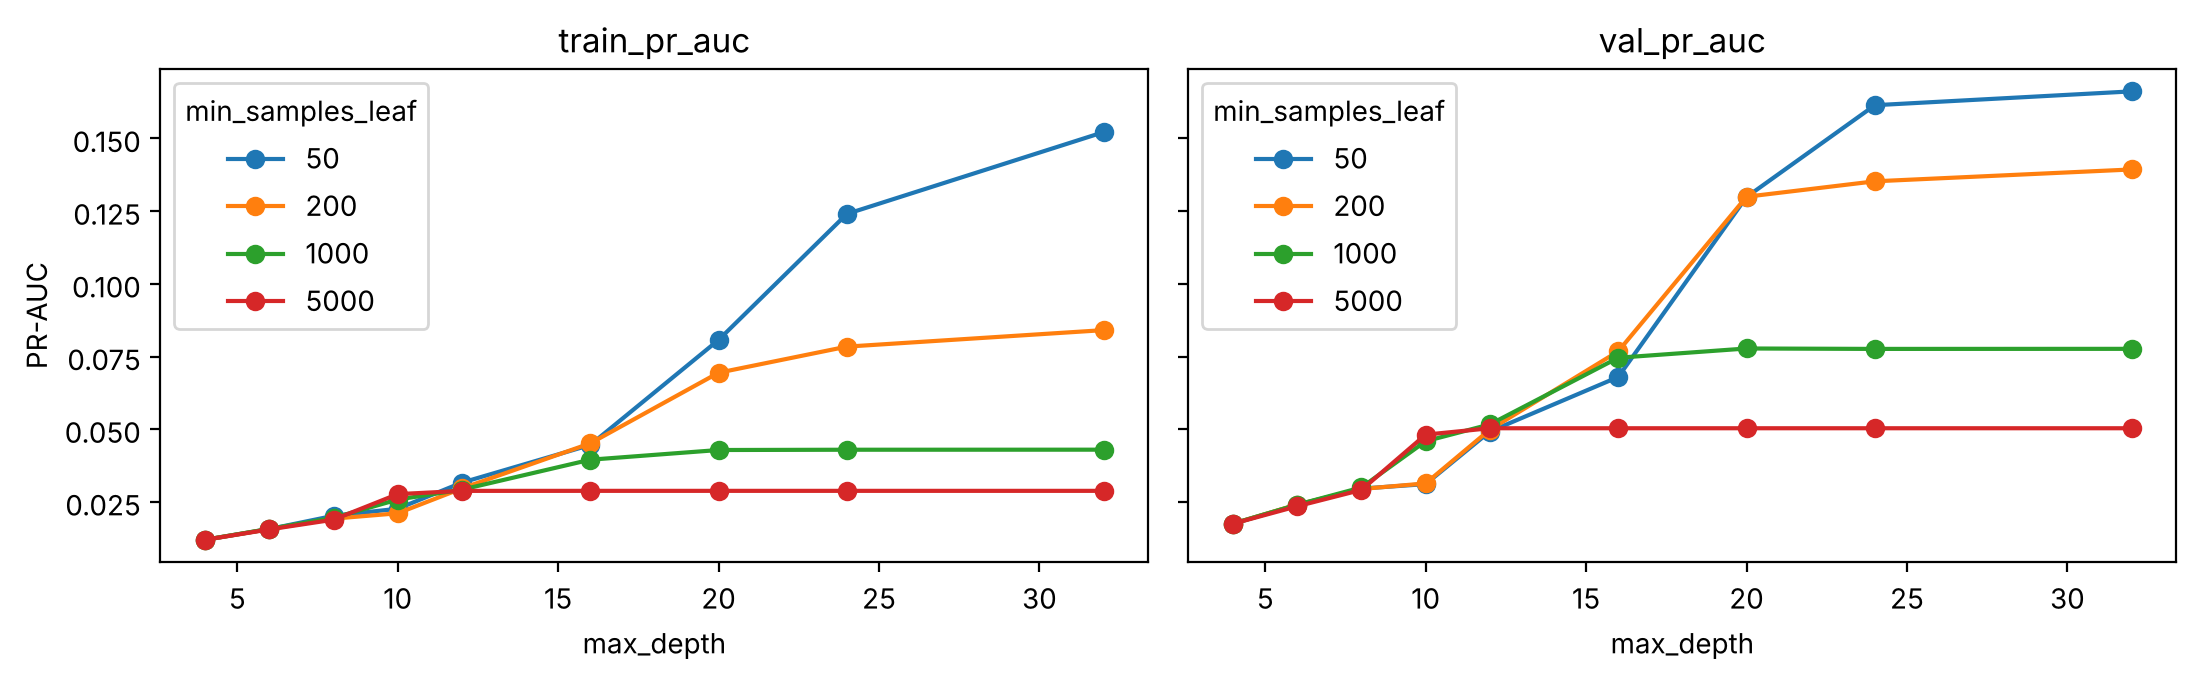

In [4]:
g = pd.read_csv(out / "grid_decision_tree.csv")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for ax, col in zip(axes, ["train_pr_auc", "val_pr_auc"]):
    g.pivot(index="max_depth", columns="min_samples_leaf", values=col).plot(marker="o", ax=ax)
    ax.set_title(col); ax.set_ylabel("PR-AUC")
plt.tight_layout(); plt.show()

### Grid-edge check
The best grid setting, `max_depth=32, min_samples_leaf=50`, sits on the edge of the grid. If a winner sits on the edge, the true best might be outside it, so this cell tries deeper trees and smaller leaves. It takes a few minutes.

In [5]:
from sklearn.metrics import average_precision_score
edge = []
for d in [32, None]:
    for leaf in [10, 20, 50]:
        p = T.build_pipeline("decision_tree", {"max_depth": d, "min_samples_leaf": leaf}, cfg).fit(X_train, y_train)
        edge.append({"max_depth": str(d), "min_samples_leaf": leaf,
                     "depth_used": p.named_steps["model"].get_depth(), "leaves": p.named_steps["model"].get_n_leaves(),
                     "train_pr_auc": average_precision_score(y_train, T.positive_scores(p, X_train)),
                     "val_pr_auc": average_precision_score(y_val, T.positive_scores(p, X_val))})
pd.DataFrame(edge).round(4)

,max_depth,min_samples_leaf,depth_used,leaves,train_pr_auc,val_pr_auc
0,32,10,32,3007,0.2713,0.1323
1,32,20,32,2538,0.2109,0.1518
2,32,50,32,1915,0.1522,0.1662
3,None,10,58,4461,0.3390,0.1207
4,None,20,55,3389,0.2413,0.1424
5,None,50,46,2172,0.1606,0.1653


Smaller leaves (10–20 rows) raise **train** PR-AUC but lower **val** PR-AUC, which is classic overfitting. An unlimited depth stops by itself around depth 46 and does no better. So `max_depth=32, min_samples_leaf=50` is a genuine optimum, not an artefact of where the grid stopped.

## 2. Validation comparison table
Each model is shown at its own val-F1-optimal threshold. PR-AUC and ROC-AUC don't depend on the threshold.

In [6]:
cols = ["pr_auc", "roc_auc", "threshold", "precision", "recall", "f1", "tp", "fp", "tn", "fn"]
table = pd.DataFrame({n: evaluate_scores(y_val, val_scores[n], m["threshold"]) for n, m in models.items()}).T[cols]
table = table.sort_values("pr_auc", ascending=False)
table.style.format({c: "{:.4f}" for c in cols[:6]} | {c: "{:,.0f}" for c in cols[6:]})

,pr_auc,roc_auc,threshold,precision,recall,f1,tp,fp,tn,fn
decision_tree,0.1662,0.7857,0.9935,0.2622,0.2043,0.2296,221,622,"1,013,898",861
logistic_regression,0.0489,0.9525,0.0203,0.0969,0.1128,0.1042,122,"1,137","1,013,383",960
naive_bayes,0.0123,0.8939,1.0000,0.0738,0.0518,0.0608,56,703,"1,013,817","1,026"


For reference, the same models at the default 0.5 threshold. `class_weight="balanced"` pushes probabilities up, so 0.5 gives high recall but very low precision.

In [7]:
pd.DataFrame({n: evaluate_scores(y_val, val_scores[n], 0.5) for n in models}).T[cols].round(4)

,pr_auc,roc_auc,threshold,precision,recall,f1,tp,fp,tn,fn
logistic_regression,0.0489,0.9525,0.5,0.0000,0.0000,0.0000,0.0,0.0,1014520.0,1082.0
naive_bayes,0.0123,0.8939,0.5,0.0028,0.9325,0.0055,1009.0,361525.0,652995.0,73.0
decision_tree,0.1662,0.7857,0.5,0.0259,0.5860,0.0496,634.0,23860.0,990660.0,448.0


## 3. Precision-recall curves on val
The dashed line is the no-skill baseline: the laundering rate, about 0.1%. PR-AUC is the area under each curve.

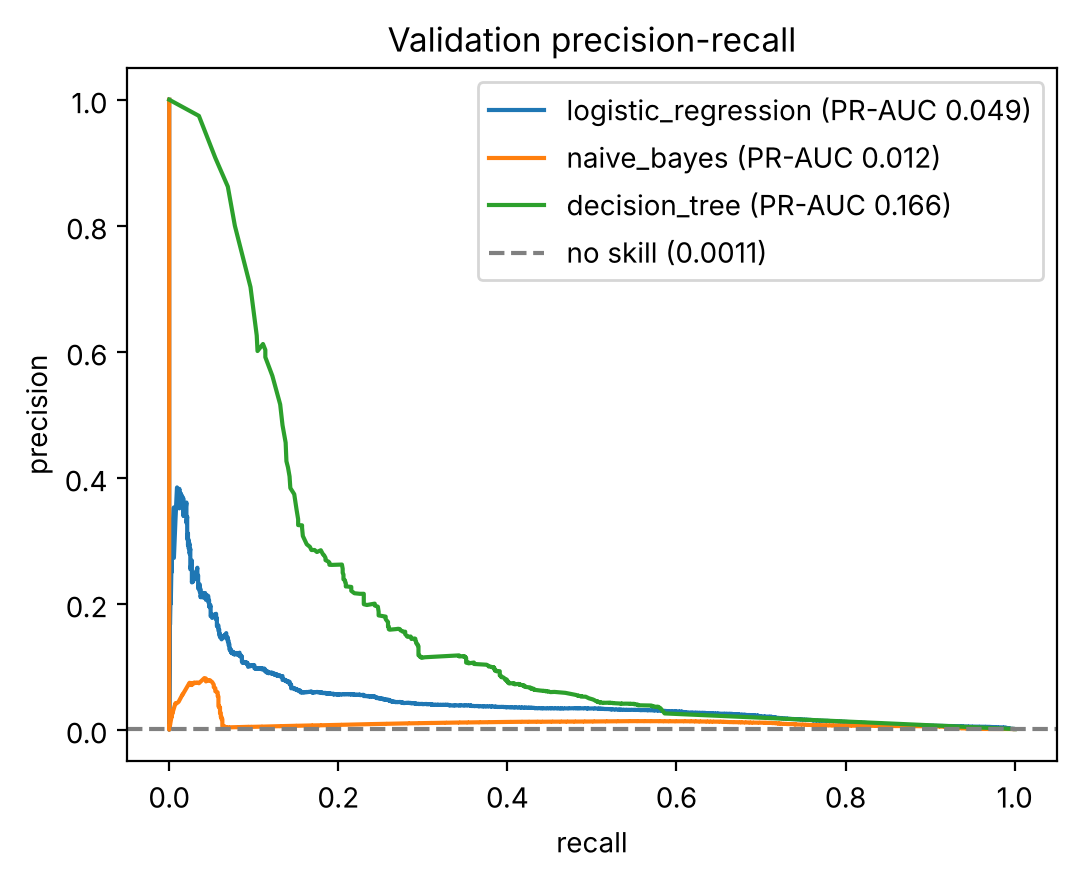

In [8]:
from sklearn.metrics import precision_recall_curve, average_precision_score
fig, ax = plt.subplots(figsize=(6, 4.5))
for n, s in val_scores.items():
    p, r, _ = precision_recall_curve(y_val, s)
    ax.plot(r, p, label=f"{n} (PR-AUC {average_precision_score(y_val, s):.3f})")
ax.axhline(y_val.mean(), ls="--", color="grey", label=f"no skill ({y_val.mean():.4f})")
ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.legend(); ax.set_title("Validation precision-recall")
plt.show()

### Naive Bayes threshold check
Naive Bayes probabilities are notoriously badly calibrated: they bunch up near 0 and 1. Sweeping the threshold shows how much the operating point matters.

In [9]:
s = val_scores["naive_bayes"]
qs = [0.5, 0.9, 0.99, 0.999, 0.9999]
pd.DataFrame({f"top {100*(1-q):.2f}% flagged": evaluate_scores(y_val, s, float(np.quantile(s, q))) for q in qs}
             | {"threshold 0.5": evaluate_scores(y_val, s, 0.5),
                "val-F1 threshold": evaluate_scores(y_val, s, models["naive_bayes"]["threshold"])}
            ).T[["threshold", "precision", "recall", "f1", "tp", "fp"]].round(4)

,threshold,precision,recall,f1,tp,fp
top 50.00% flagged,0.0758,0.0020,0.9482,0.0040,1026.0,506775.0
top 10.00% flagged,1.0000,0.0080,0.7523,0.0159,814.0,100747.0
top 1.00% flagged,1.0000,0.0067,0.0628,0.0121,68.0,10089.0
top 0.10% flagged,1.0000,0.0591,0.0573,0.0582,62.0,987.0
top 0.01% flagged,1.0000,0.0000,0.0000,0.0000,0.0,103.0
threshold 0.5,0.5000,0.0028,0.9325,0.0055,1009.0,361525.0
val-F1 threshold,1.0000,0.0738,0.0518,0.0608,56.0,703.0


## 4. What drives each model?

In [10]:
interp = pd.DataFrame({
    "LR coefficient (log-odds per SD)": T.logistic_coefficients(models["logistic_regression"]["pipeline"]),
    "Tree importance": T.tree_importances(models["decision_tree"]["pipeline"]),
    "NB class separation (SDs)": T.naive_bayes_separation(models["naive_bayes"]["pipeline"]),
})
interp.sort_values("Tree importance", ascending=False).round(3)

,LR coefficient (log-odds per SD),Tree importance,NB class separation (SDs)
cat__payment_format_ACH,2.438,0.541,2.075
counts__sender_unique_receivers_24h,0.577,0.181,0.100
amount__log_amount_paid,0.365,0.093,0.476
counts__sender_txn_count_1h,0.403,0.055,0.060
counts__receiver_txn_count_1h,-0.779,0.043,-0.193
counts__sender_txn_count_24h,-0.302,0.027,0.044
counts__receiver_txn_count_24h,-0.740,0.015,-0.040
counts__receiver_unique_senders_24h,0.905,0.008,0.109
cat__payment_currency_US Dollar,-0.448,0.006,0.011
bool__same_bank,-1.789,0.005,-0.618


In [11]:
from sklearn.tree import export_text
tree_pipe = models["decision_tree"]["pipeline"]
print(export_text(tree_pipe.named_steps["model"], feature_names=T.feature_names(tree_pipe), max_depth=3))

|--- cat__payment_format_ACH <= 0.50
|   |--- counts__sender_unique_receivers_24h <= 25.50
|   |   |--- cat__payment_currency_Bitcoin <= 0.50
|   |   |   |--- counts__receiver_txn_count_1h <= 5.50
|   |   |   |   |--- truncated branch of depth 15
|   |   |   |--- counts__receiver_txn_count_1h >  5.50
|   |   |   |   |--- truncated branch of depth 5
|   |   |--- cat__payment_currency_Bitcoin >  0.50
|   |   |   |--- counts__sender_txn_count_24h <= 0.50
|   |   |   |   |--- truncated branch of depth 12
|   |   |   |--- counts__sender_txn_count_24h >  0.50
|   |   |   |   |--- truncated branch of depth 7
|   |--- counts__sender_unique_receivers_24h >  25.50
|   |   |--- counts__sender_unique_receivers_24h <= 10524.50
|   |   |   |--- counts__sender_unique_receivers_24h <= 4559.50
|   |   |   |   |--- truncated branch of depth 29
|   |   |   |--- counts__sender_unique_receivers_24h >  4559.50
|   |   |   |   |--- truncated branch of depth 29
|   |   |--- counts__sender_unique_receivers_24h